# 03 · Workloads: where the GPU-hours are, and how flexible they are

**Question.** The router moves AI work in time and space. Which real workload traces can stand in for an AI cluster, where does the energy actually go (which jobs, how long, how big), what evidence is there that the work can wait, pause or move, how much energy is one GPU-hour, and how do a few weeks of trace become a year of simulated load?

**Short answer.**
- **Acme Seren** (Shanghai AI Lab, 2023, LLM development) is the primary trace, **Alibaba PAI 2020** the robustness trace, and the **Alibaba 2026 spot** trace only anchors how much work operators already treat as preemptible.
- **The tail carries the energy.** In Seren, jobs longer than 6 hours are 1.1 % of jobs but 89 % of GPU-hours; pre-training is 0.9 % of GPU jobs and 70 % of GPU-hours. Savings will come from when big jobs start and whether they pause, not from delaying small ones.
- **Flexibility is plausible but not measured.** Queues are about a second today, so no trace measures tolerance to waiting: allowed wait is an *assumed* sweep. Long runs already stop and resume from checkpoints, and the scheduler already preempts evaluations.
- **About 0.7 kWh per GPU-hour** at the meter (*modeled* from *measured* A100 power and an *assumed* PUE), swept 0.4–2.0.

**How to read this notebook.** Trace fields are *measured*; GPU-hours are derived from them; energy is *modeled*. Figures and statistics come from `lab/scripts/recon_traces_profile.py`, the code behind [`docs/data-profile/workloads-prices.md` §1](../docs/data-profile/workloads-prices.md#1-workload-traces).

**Seal.** The traces hold no grid or price values, and nothing here joins them to grid data. `drop_sealed` is still applied to their submit times as a guard (§0).

## 0. Inputs and the seal

In [1]:
import json
import shutil
import tempfile
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from gridpilot import notebook as nb
from gridpilot.data import traces as T
from gridpilot.paths import MANIFEST_DIR
from gridpilot.splits import TEST_START, drop_sealed

nb.setup()
SCRATCH = Path(tempfile.mkdtemp(prefix="nb03_"))
rt = nb.import_recon("recon_traces_profile", SCRATCH)

snapshot = json.loads((MANIFEST_DIR / "snapshot.json").read_text())
pl.DataFrame([{"manifest": k, "files": v["files"], "MB": round(v["bytes"] / 1e6, 1), "status": v["status"],
               "manifest_sha256": v["manifest_sha256"]} for k, v in snapshot["sources"].items() if k.startswith("traces_")])

manifest,files,MB,status,manifest_sha256
"""traces_acme""",14,108.5,"""frozen""","""636d81a7c3a75dc823933368175e1cc0badcac9e7164584268611072fa0ccd31"""
"""traces_alibaba_spot2026""",4,23.2,"""frozen""","""42d8e490f4aba2db4acdc0332562604c8902f0a4cc20bf060d872748e4caf56a"""
"""traces_pai2020""",12,558.8,"""frozen""","""1328d822040abf5b3aa0566f0932a4bc3bb84d295ef82ce60d583321c5f4ba8c"""


In [2]:
raw = T.load_all()
# drop_sealed filters on ts < TEST_START, which also drops rows whose timestamp is null. Some PAI jobs
# have no submit time; they are not in the sealed window, so they are kept explicitly.
df = pl.concat([drop_sealed(raw, "submit_ts"), raw.filter(pl.col("submit_ts").is_null())])
assert df.height == raw.height and raw.filter(pl.col("submit_ts") >= TEST_START).is_empty()
(raw.group_by("trace").agg(pl.len().alias("jobs"), pl.col("submit_ts").null_count().alias("no_submit_time"),
                           (pl.col("submit_ts") >= TEST_START).sum().alias("in_sealed_window"),
                           pl.col("submit_ts").min().alias("first_submit"), pl.col("submit_ts").max().alias("last_submit"))
 .sort("trace"))

trace,jobs,no_submit_time,in_sealed_window,first_submit,last_submit
"""acme_kalos""",62413,0,0,2023-05-17 11:00:58 UTC,2023-08-16 15:18:02 UTC
"""acme_seren""",818327,0,0,2023-02-28 16:18:22 UTC,2023-08-16 15:59:42 UTC
"""pai2020""",1055501,3663,0,1970-01-06 17:18:39 UTC,1970-03-16 15:58:01 UTC
"""spot2026""",466867,0,0,1970-01-01 00:00:00 UTC,1970-07-04 01:21:10 UTC


**What the table shows.** No job falls in the sealed window: Acme is from 2023, and PAI's timestamps are shifted to fake dates (their time of day and weekday are true, UTC+8; they read as early 1970 here). The spot trace has only seconds since its first submission, so its "dates" also sit at 1970 and carry no calendar meaning; it is used only for shares, never for timing. PAI has a few thousand jobs without a submit time; a plain `drop_sealed` would silently drop them (a null timestamp fails the `< TEST_START` test), so they are kept explicitly.

## 1. Three traces

Size and shape of the GPU jobs in each trace (CPU-only jobs dropped). Run time is end minus start; GPU-hours are GPUs × run time. PAI's failed jobs mostly have no end time, so its run-time statistics cover the 70 % of GPU jobs with one.

In [3]:
stats = {name: rt.profile_trace(df, name) for name in ("acme_seren", "acme_kalos", "pai2020")}
stats["spot2026"] = rt.spot_stats(df)
rows = []
for name in ("acme_seren", "acme_kalos", "pai2020"):
    s = stats[name]
    rows.append({"trace": name, "jobs": s["jobs_total"], "gpu_jobs": s["gpu_jobs"], "with_run_time": s["gpu_jobs_with_run"],
                 "span_days": round(s["span_days"], 1), "GPU_hours_M": round(s["gpu_hours"] / 1e6, 2),
                 "mean_GPUs_busy": round(s["mean_gpus_busy"]),
                 "run_p50_min": round(s["run_s"]["p50"] / 60, 1), "run_p90_min": round(s["run_s"]["p90"] / 60, 1),
                 "run_p99_h": round(s["run_s"]["p99"] / 3600, 1), "GPUs_p50": s["gpu_count"]["p50"],
                 "GPUs_p99": s["gpu_count"]["p99"], "GPUs_max": s["gpu_count"]["max"],
                 "jobs_with_le_1_GPU_%": round(100 * s["share_jobs_single_gpu_or_less"], 1)})
pl.DataFrame(rows)

trace,jobs,gpu_jobs,with_run_time,span_days,GPU_hours_M,mean_GPUs_busy,run_p50_min,run_p90_min,run_p99_h,GPUs_p50,GPUs_p99,GPUs_max,jobs_with_le_1_GPU_%
"""acme_seren""",818327,450590,450590,169.0,5.63,1387,2.2,21.6,7.0,1.0,64.0,1024.0,54.0
"""acme_kalos""",62413,19907,19907,91.2,1.48,677,2.1,24.7,3.8,1.0,1024.0,1024.0,86.3
"""pai2020""",1055501,1017904,715487,68.9,4.73,2860,10.8,215.7,19.3,1.0,35.0,1000.0,78.0


## 2. Where the GPU-hours are

GPU-hours are a direct proxy for energy. The table shows how small a share of jobs carries most of them.

In [4]:
pl.DataFrame([{"trace": n, **{f"{k}_%": round(100 * stats[n][k], 1) for k in (
    "share_jobs_gt_1h", "share_gpuh_gt_1h", "share_jobs_gt_6h", "share_gpuh_gt_6h", "share_jobs_gt_24h",
    "share_gpuh_gt_24h", "share_gpuh_ge_64gpus", "share_gpuh_ge_256gpus")}} for n in ("acme_seren", "acme_kalos", "pai2020")])

trace,share_jobs_gt_1h_%,share_gpuh_gt_1h_%,share_jobs_gt_6h_%,share_gpuh_gt_6h_%,share_jobs_gt_24h_%,share_gpuh_gt_24h_%,share_gpuh_ge_64gpus_%,share_gpuh_ge_256gpus_%
"""acme_seren""",4.7,95.1,1.1,88.9,0.3,64.0,80.7,56.4
"""acme_kalos""",3.6,95.4,0.7,85.7,0.2,57.7,98.0,96.3
"""pai2020""",26.1,93.5,5.8,68.2,0.7,30.0,10.6,0.5


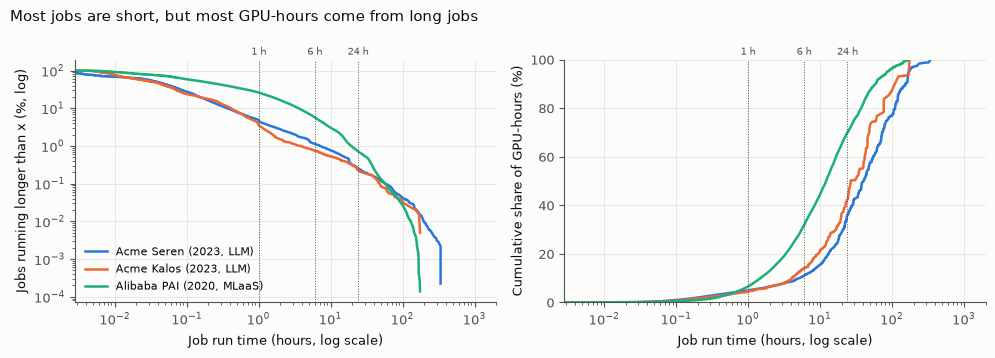

In [5]:
rt.fig_durations(df)
nb.show(SCRATCH / "traces_duration_and_gpuhours.png")

**What the figure shows.** Left: the share of jobs that run longer than a given time, on log axes. Most jobs finish within minutes (the curves fall steeply). Right: the cumulative share of GPU-hours, ordered by run time. The curves stay near zero until about an hour and then climb: in both Acme clusters, jobs under an hour hold only about 5 % of the GPU-hours, and jobs over a day hold 58–64 %. PAI's curve rises earlier, because its work is many medium-length jobs.

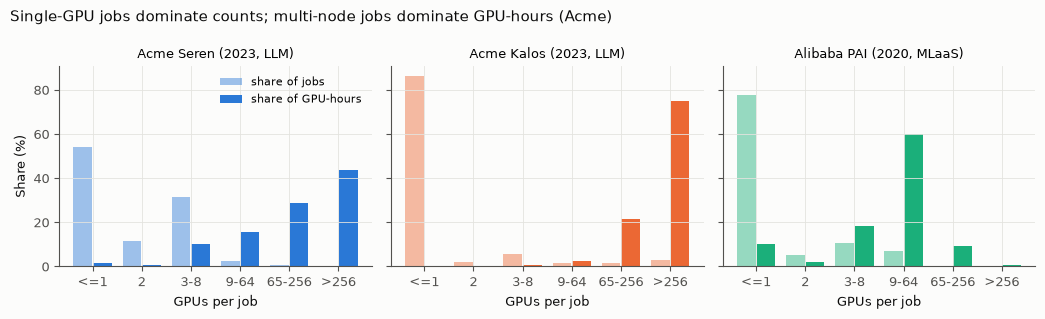

In [6]:
rt.fig_gpu_count(df)
nb.show(SCRATCH / "traces_gpu_count.png")

**What the figure shows.** For each trace, pale bars are the share of jobs and dark bars the share of GPU-hours, by GPUs per job. Single-GPU jobs dominate the counts everywhere, but in Acme the GPU-hours sit in multi-node jobs: jobs with 64 or more GPUs carry 81 % of Seren's GPU-hours and 98 % of Kalos's (table above). PAI is the opposite: small, often fractional-GPU jobs carry most of its work. That is why PAI is the robustness case.

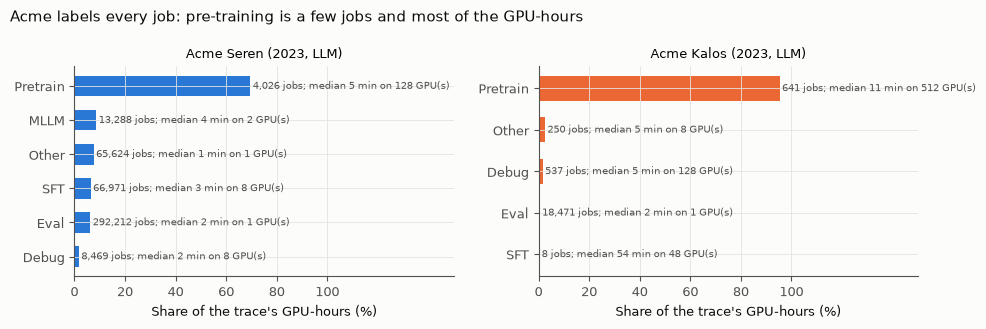

job_type,jobs,GPU_h_%,median_run_min,med_gpus,failed_%,cancelled_%,preempted_%
"""Pretrain""",4026,69.5,5.1,128.0,13.8,61.1,1.0
"""MLLM""",13288,8.6,4.2,2.0,39.9,23.6,1.3
"""Other""",65624,7.6,1.4,1.0,41.3,19.6,0.3
"""SFT""",66971,6.4,3.3,8.0,28.9,8.3,4.0
"""Eval""",292212,6.2,2.2,1.0,33.8,6.3,13.9
"""Debug""",8469,1.7,1.9,8.0,22.5,41.8,0.3


In [7]:
rt.fig_types(stats)
nb.show(SCRATCH / "traces_acme_job_types.png")
types = pl.DataFrame(stats["acme_seren"]["by_type"]).filter(pl.col("job_type") != "CPU")
types.select("job_type", "jobs", (pl.col("gpuh_share") * 100).round(1).alias("GPU_h_%"),
             (pl.col("med_run_s") / 60).round(1).alias("median_run_min"), "med_gpus",
             (pl.col("fail_rate") * 100).round(1).alias("failed_%"), (pl.col("cancel_rate") * 100).round(1).alias("cancelled_%"),
             (pl.col("preempt_rate") * 100).round(1).alias("preempted_%"))

**What the figure and table show.** Acme labels every job with its purpose. In Seren, the 4,026 pre-training jobs (0.9 % of GPU jobs) carry 69.5 % of the GPU-hours, at a median of 128 GPUs; evaluations are two-thirds of the jobs and 6 % of the GPU-hours. Note that the *median* pre-training job is short (about 5 minutes): many are launches that fail or get stopped early, and a few very long runs carry the hours.

## 3. Flexibility evidence

Nothing in a trace measures how long a job *could* have waited: we only see what happened. The table collects the evidence that bounds the assumptions the simulator needs.

In [8]:
seren, kalos, pai = stats["acme_seren"], stats["acme_kalos"], stats["pai2020"]
spot = pl.DataFrame(stats["spot2026"]["by_type"])
spot_share = spot.filter(pl.col("job_type") == "Spot")
batch = types.filter(pl.col("job_type").is_in(["Pretrain", "SFT", "MLLM", "Eval"]))["gpuh_share"].sum()


def small_jobs(name: str) -> tuple[float, float]:
    g = df.filter((pl.col("trace") == name) & (pl.col("gpu_count") > 0))
    k = g.filter(pl.col("run_s").is_not_null())
    return (float((g["gpu_count"] <= 8).mean()),
            float(k.filter(pl.col("gpu_count") <= 8)["gpu_hours"].sum() / k["gpu_hours"].sum()))


rows = [
    ("Queue time today, Seren (median / p90 / p99)",
     f"{seren['queue_s']['p50']:.0f} s / {seren['queue_s']['p90'] / 60:.1f} min / {seren['queue_s']['p99'] / 3600:.1f} h"),
    ("Seren jobs that waited more than 1 h", f"{100 * seren['share_queued_gt_1h']:.1f} %"),
    ("Kalos queue median; jobs waiting > 1 h", f"{kalos['queue_s']['p50']:.0f} s; {100 * kalos['share_queued_gt_1h']:.1f} %"),
    ("Seren GPU-hours in batch types (Pretrain, SFT, MLLM, Eval)", f"{100 * batch:.1f} %"),
    ("Seren GPU-hours ending 'cancelled' (how long runs end)", f"{100 * seren['status_share_gpuh']['cancelled']:.1f} %"),
    ("Seren jobs preempted by the scheduler", f"{100 * seren['status_share_jobs']['preempted']:.1f} %"),
    ("Spot 2026: Spot share of jobs / of GPU-hours",
     f"{100 * spot_share['job_share'].item():.1f} % / {100 * spot_share['gpuh_share'].item():.1f} %"),
    *[(f"{n}: jobs with <= 8 GPUs (one node) / their GPU-hours", "{:.1f} % / {:.1f} %".format(*(100 * x for x in small_jobs(n))))
      for n in ("acme_seren", "acme_kalos", "pai2020")],
]
pl.DataFrame(rows, schema=["evidence", "value"], orient="row")

evidence,value
"""Queue time today, Seren (median / p90 / p99)""","""1 s / 3.5 min / 1.5 h"""
"""Seren jobs that waited more than 1 h""","""1.4 %"""
"""Kalos queue median; jobs waiting > 1 h""","""17 s; 1.2 %"""
"""Seren GPU-hours in batch types (Pretrain, SFT, MLLM, Eval)""","""90.7 %"""
"""Seren GPU-hours ending 'cancelled' (how long runs end)""","""67.2 %"""
"""Seren jobs preempted by the scheduler""","""9.7 %"""
"""Spot 2026: Spot share of jobs / of GPU-hours""","""11.0 % / 2.4 %"""
"""acme_seren: jobs with <= 8 GPUs (one node) / their GPU-hours""","""96.7 % / 11.9 %"""
"""acme_kalos: jobs with <= 8 GPUs (one node) / their GPU-hours""","""93.9 % / 0.6 %"""
"""pai2020: jobs with <= 8 GPUs (one node) / their GPU-hours""","""92.6 % / 30.5 %"""


**What the table says about each assumption.**
- **Allowed wait.** Today almost nobody waits (Seren: a median of 1 second). There is no measured tolerance, so the allowed wait is an *assumed* sweep (0–48 h), and it should scale with job size: waiting 6 h is not credible for a 2-minute evaluation, but it is for a 3-day pre-training run.
- **Deferrable share.** Batch work is about 91 % of Seren's GPU-hours. The operators' own preemptible class (Spot) is 2.4 % of GPU-hours in the 2026 trace: the floor that is already treated as flexible. The sweep runs between the two.
- **Interruptible.** Long LLM runs already stop and resume from checkpoints ("cancelled" is how 67 % of Seren's GPU-hours end, which is not waste), and the scheduler already preempts 9.7 % of jobs, mostly evaluations. Pausing pre-training through a dirty hour therefore needs an *assumed* restart cost, not a new mechanism.
- **Movable.** Single-node jobs (≤ 8 GPUs) are almost all of the jobs but little of the energy in Acme. Multi-node pre-training can only move before it starts (data gravity, *assumed*). Every GPU-hour counts as load, whatever the job's final state.

## 4. Arrivals and cluster load

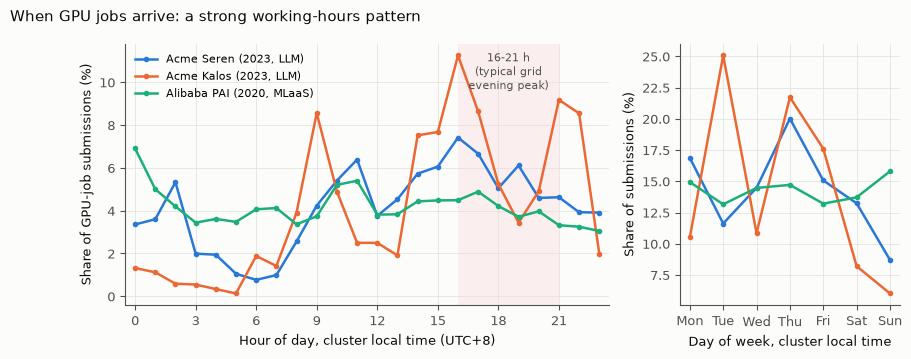

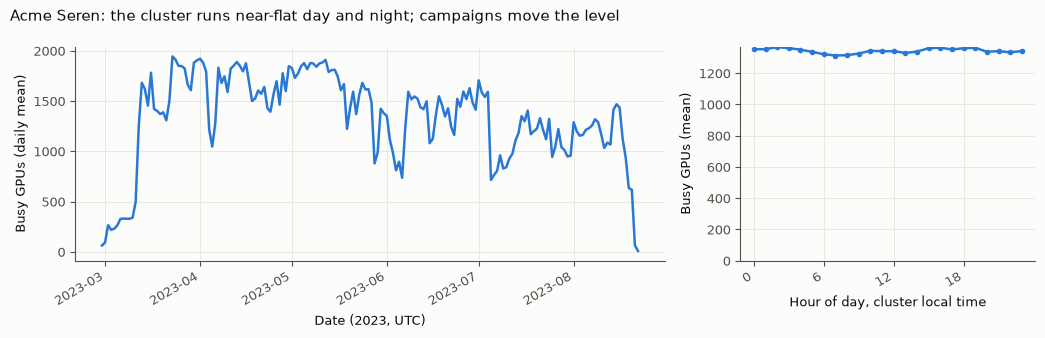

Seren busy GPUs: mean 1390 (61% of 2288), p05 620, p95 1925 (84%); hour-of-day profile max/min 1.04


In [9]:
rt.fig_arrivals(df, stats)
nb.show(SCRATCH / "traces_arrivals_hour_dow.png")
busy = rt.fig_busy(df)["acme_seren"]
nb.show(SCRATCH / "traces_seren_busy_gpus.png")
SEREN_GPUS = 2288  # cluster size from the NSDI '24 paper
print(f"Seren busy GPUs: mean {busy['busy_gpus_mean']:.0f} ({busy['busy_gpus_mean'] / SEREN_GPUS:.0%} of {SEREN_GPUS}), "
      f"p05 {busy['busy_gpus_p05']:.0f}, p95 {busy['busy_gpus_p95']:.0f} ({busy['busy_gpus_p95'] / SEREN_GPUS:.0%}); "
      f"hour-of-day profile max/min {busy['hour_of_day_profile_max_over_min']:.2f}")

**What the figures show.** First figure: Acme jobs are submitted in working hours, with a large afternoon block (30 % of Seren submissions fall at 16:00–21:00 local, the hours a US grid calls its evening peak); PAI is nearly flat. Second figure: even so, Seren's *running* load is flat across the day (max/min 1.04), because long multi-node jobs smooth it out; the level moves with training campaigns. The cluster runs at about 61 % of its GPUs on average and 84 % on busy days, so there is headroom for shifting, but not unlimited: a GPU capacity cap is mandatory, or deferral would invent free capacity off-peak.

## 5. Energy per GPU-hour

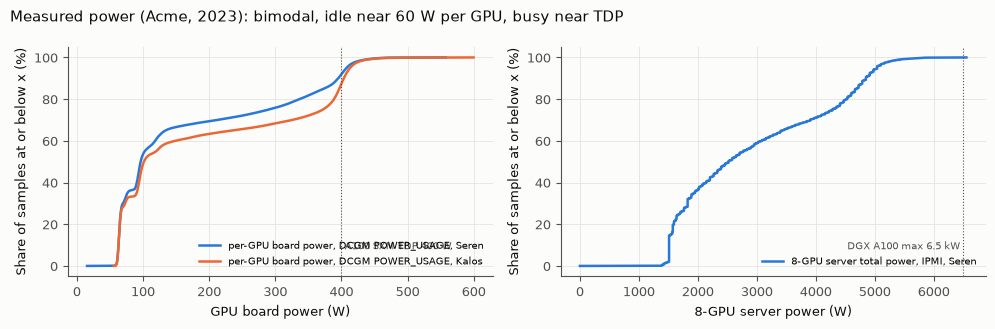

series,p10,p25,p50,p75,p90,max,mean
"""gpu_power_seren_w""",63.0,66.2,96.5,290.2,395.1,558.0,168.7
"""gpu_power_kalos_w""",63.0,66.4,101.4,371.8,403.6,599.7,191.7
"""gpu_server_power_w""",1512.0,1692.5,2520.0,4284.0,4851.0,6554.0,2933.3


In [10]:
power = rt.fig_power()
nb.show(SCRATCH / "traces_acme_power_cdf.png")
pl.DataFrame([{"series": k, **{q: round(v[q], 1) for q in ("p10", "p25", "p50", "p75", "p90", "max", "mean")}}
              for k, v in power.items()])

**What the figure shows.** Measured power in Acme (2023) is bimodal: a GPU idles near 60–66 W and works near its 400 W limit; an 8-GPU server spends its busy hours at 4.3–4.9 kW and peaks at its 6.5 kW rating. The base case and the sweep follow from these measurements and from spec sheets:

In [11]:
srv = power["gpu_server_power_w"]
cases = [
    ("low: A100 server mean incl. idle, PUE 1.1 (hyperscale)", srv["mean"] / 8 / 1000, 1.1),
    ("base: busy A100 slot (~0.6 kW, measured p75-p90 band), PUE 1.2", 0.6, 1.2),
    ("busy band low end (p75 server / 8), PUE 1.2", srv["p75"] / 8 / 1000, 1.2),
    ("busy band high end (p90 server / 8), PUE 1.2", srv["p90"] / 8 / 1000, 1.2),
    ("high: H100-class system max (10.2 kW / 8), PUE 1.56 (industry average)", 10.2 / 8, 1.56),
]
pl.DataFrame([{"case": c, "IT_kW_per_GPU": round(kw, 2), "PUE": p, "kWh_per_GPU_hour_at_meter": round(kw * p, 2)}
              for c, kw, p in cases])

case,IT_kW_per_GPU,PUE,kWh_per_GPU_hour_at_meter
"""low: A100 server mean incl. idle, PUE 1.1 (hyperscale)""",0.37,1.1,0.4
"""base: busy A100 slot (~0.6 kW, measured p75-p90 band), PUE 1.2""",0.6,1.2,0.72
"""busy band low end (p75 server / 8), PUE 1.2""",0.54,1.2,0.64
"""busy band high end (p90 server / 8), PUE 1.2""",0.61,1.2,0.73
"""high: H100-class system max (10.2 kW / 8), PUE 1.56 (industry average)""",1.27,1.56,1.99


**The choice.** 0.6 kWh of IT energy per busy A100-class GPU-hour × PUE 1.2 ≈ **0.7 kWh per GPU-hour at the meter** (*modeled*), swept from about 0.4 to 2.0. The top of the range uses a system maximum, not a measured average, so it is an upper bound. Per-job utilization varies tenfold (PAI), so a constant per GPU-hour, labelled *assumed* with this range, is the defensible simple choice.

## 6. Mapping weeks of trace onto a year of grid hours

The traces are short: Seren covers about 24 weeks, Kalos 13 and PAI 10. The grid year needs 52. The options from the profile:

| Option | How | Kept because / rejected because |
|---|---|---|
| **A. Week-block bootstrap (chosen)** | draw whole trace weeks with replacement, aligned by weekday and local wall-clock hour; one seed per replicate | keeps daily, weekly and within-week job structure; seeds give confidence intervals. It is `simulated`, repeats real campaigns in random seasons, and has no growth trend |
| B. Tile the trace in order | repeat Seren's 24 weeks 2.2 times | rejected: the same campaign hits the same grid weeks; the copies add no information |
| C. Generative model | Poisson arrivals from the hour-of-week rate, attributes resampled | rejected: loses the campaign burstiness that carries the GPU-hours (≥ 64-GPU jobs are 81 % of Seren's) |
| D. Seasonal replay | replay the same 24 weeks once per season | rejected: the same work in every season, overlapping copies |

**Time-zone alignment.** A submission at 10:00 at the cluster (UTC+8) becomes 10:00 in Utah, keeping the human working-hours pattern. The figure shows what happens otherwise: aligned by UTC, Chinese mornings land in the US evening.

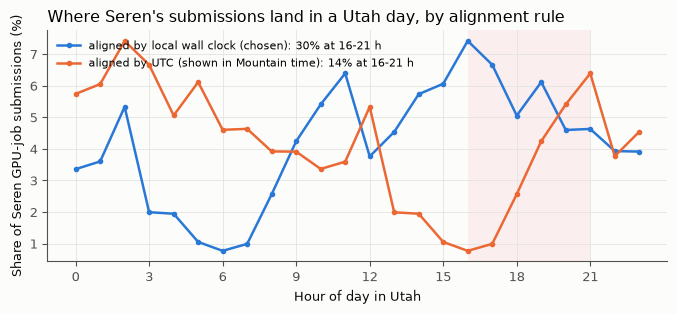

In [12]:
seren_jobs = df.filter((pl.col("trace") == "acme_seren") & (pl.col("gpu_count") > 0))
wall = seren_jobs["submit_local"].dt.hour().to_numpy()
utc = seren_jobs["submit_ts"].dt.convert_time_zone("America/Denver").dt.hour().to_numpy()
fig, ax = plt.subplots(figsize=(8, 3))
for hours, label, color in ((wall, "aligned by local wall clock (chosen)", "#2a78d6"),
                            (utc, "aligned by UTC (shown in Mountain time)", "#eb6834")):
    share = np.bincount(hours, minlength=24) / len(hours) * 100
    ax.plot(range(24), share, marker="o", ms=3, color=color,
            label=f"{label}: {share[16:21].sum():.0f}% at 16-21 h")
ax.axvspan(16, 21, color="#e34948", alpha=0.07, lw=0)
ax.set(xlabel="Hour of day in Utah", ylabel="Share of Seren GPU-job submissions (%)", xticks=range(0, 24, 3))
ax.legend(fontsize=8, loc="upper left")
ax.set_title("Where Seren's submissions land in a Utah day, by alignment rule", loc="left")
plt.show()

In [13]:
spans = {n: stats[n]["span_days"] / 7 for n in ("acme_seren", "acme_kalos", "pai2020")}
it_mw = [busy["busy_gpus_mean"] * kw / 1000 for kw in (srv["mean"] / 8 / 1000, srv["p90"] / 8 / 1000)]
print("trace spans (weeks):", {k: round(v, 1) for k, v in spans.items()})
print(f"Seren as recorded: {busy['busy_gpus_mean']:.0f} busy GPUs x {srv['mean'] / 8 / 1000:.2f}-{srv['p90'] / 8 / 1000:.2f} kW "
      f"= {it_mw[0]:.2f}-{it_mw[1]:.2f} MW of IT load (modeled); a Utah-scale scenario needs a stated multiplier (assumed)")
shutil.rmtree(SCRATCH)

trace spans (weeks): {'acme_seren': 24.1, 'acme_kalos': 13.0, 'pai2020': 9.8}
Seren as recorded: 1390 busy GPUs x 0.37-0.61 kW = 0.51-0.84 MW of IT load (modeled); a Utah-scale scenario needs a stated multiplier (assumed)


**What the figure and numbers show.** With wall-clock alignment, the afternoon submission block lands in Utah's afternoon and evening, as it would for a US team. With UTC alignment, the cluster's quiet early morning would land in Utah's afternoon and its busy afternoon in Utah's small hours: an artefact of geography, not behaviour. And Seren as recorded is a modest load, well under a megawatt of IT power: any Utah-scale scenario (for example, tens of MW) must state how it scales the trace, and label the multiplier *assumed*.

## Decisions this supports

From the [decision log](../docs/decisions.md):
- **D-033**: Acme Seren is the primary trace, PAI 2020 the robustness trace, the spot 2026 trace only an anchor for the preemptible share (§1–§3).
- **D-034**: every GPU-hour counts as load; the levers are start time and pause/resume of long jobs; allowed wait is an assumed sweep; a GPU capacity cap is mandatory (§2–§4).
- **D-035**: 0.7 kWh per GPU-hour at the meter, swept 0.4–2.0 (§5).
- **D-036**: week-block bootstrap aligned by local wall clock, with a stated scale multiplier (§6).
- **D-014**: work accounting and a seeded, block-based trace mapping described as a synthetic workload over real grid hours (§6).